In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"D:\multimodal_emotion_project")
DATA_DIR = PROJECT_DIR / "data" / "processed"
MANIFEST_PATH = DATA_DIR / "manifest.csv"

manifest = pd.read_csv(MANIFEST_PATH)
manifest = manifest[manifest["preprocessing_status"] == "ok"].copy()

print("Total valid clips:", len(manifest))
print("Unique actors:", sorted(manifest["actor_id"].unique()))
print("Number of emotions:", manifest["emotion"].nunique())

display(manifest.head())

Total valid clips: 360
Unique actors: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Number of emotions: 8


,emotion_code,emotion,actor_id,gender,statement,intensity,repetition,clip_id,video_path,audio_feature,video_feature,preprocessing_status,error
0,1,neutral,1,male,1,1,1,01-01-01-01-01-01-01,data\raw\RAVDESS\Video_Speech_Actor_01\Actor_0...,data\processed\audio\01-01-01-01-01-01-01.npy,data\processed\video\01-01-01-01-01-01-01.npy,ok,NaN
1,1,neutral,1,male,1,1,2,01-01-01-01-01-02-01,data\raw\RAVDESS\Video_Speech_Actor_01\Actor_0...,data\processed\audio\01-01-01-01-01-02-01.npy,data\processed\video\01-01-01-01-01-02-01.npy,ok,NaN
2,1,neutral,1,male,2,1,1,01-01-01-01-02-01-01,data\raw\RAVDESS\Video_Speech_Actor_01\Actor_0...,data\processed\audio\01-01-01-01-02-01-01.npy,data\processed\video\01-01-01-01-02-01-01.npy,ok,NaN
3,1,neutral,1,male,2,1,2,01-01-01-01-02-02-01,data\raw\RAVDESS\Video_Speech_Actor_01\Actor_0...,data\processed\audio\01-01-01-01-02-02-01.npy,data\processed\video\01-01-01-01-02-02-01.npy,ok,NaN
4,2,calm,1,male,1,1,1,01-01-02-01-01-01-01,data\raw\RAVDESS\Video_Speech_Actor_01\Actor_0...,data\processed\audio\01-01-02-01-01-01-01.npy,data\processed\video\01-01-02-01-01-01-01.npy,ok,NaN


emotion
angry        48
calm         48
disgust      48
fearful      48
happy        48
neutral      24
sad          48
surprised    48
Name: count, dtype: int64

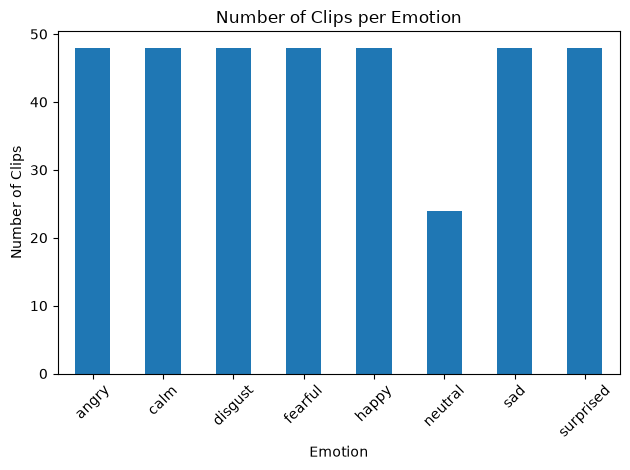

In [7]:
emotion_counts = manifest["emotion"].value_counts().sort_index()

display(emotion_counts)

emotion_counts.plot(kind="bar")
plt.title("Number of Clips per Emotion")
plt.xlabel("Emotion")
plt.ylabel("Number of Clips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

emotion,angry,calm,disgust,fearful,happy,neutral,sad,surprised
actor_id,,,,,,,,
1,8,8,8,8,8,4,8,8
2,8,8,8,8,8,4,8,8
3,8,8,8,8,8,4,8,8
4,8,8,8,8,8,4,8,8
5,8,8,8,8,8,4,8,8
6,8,8,8,8,8,4,8,8


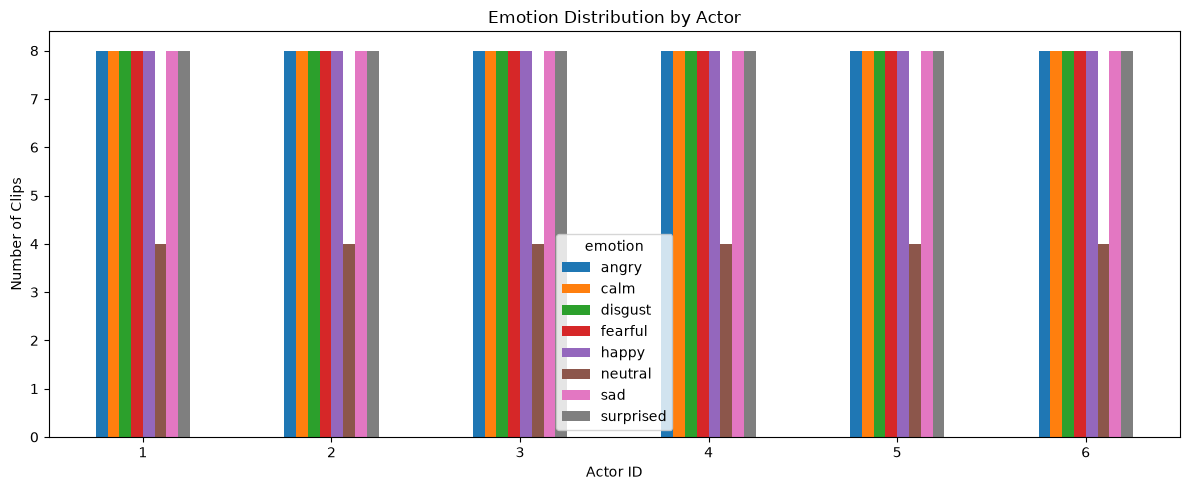

In [8]:
actor_counts = (
    manifest.groupby(["actor_id", "emotion"])
    .size()
    .unstack(fill_value=0)
)

display(actor_counts)

actor_counts.plot(kind="bar", figsize=(12, 5))
plt.title("Emotion Distribution by Actor")
plt.xlabel("Actor ID")
plt.ylabel("Number of Clips")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
sample = manifest.iloc[0]

audio_path = Path(sample["audio_feature"])
video_path = Path(sample["video_feature"])

if not audio_path.is_absolute():
    audio_path = PROJECT_DIR / audio_path

if not video_path.is_absolute():
    video_path = PROJECT_DIR / video_path

audio = np.load(audio_path)
video = np.load(video_path)

print("Emotion:", sample["emotion"])
print("Actor ID:", sample["actor_id"])
print("Audio shape:", audio.shape)
print("Video shape:", video.shape)
print("Audio range:", float(audio.min()), "to", float(audio.max()))
print("Video range:", int(video.min()), "to", int(video.max()))

Emotion: neutral
Actor ID: 1
Audio shape: (96, 251)
Video shape: (8, 224, 224, 3)
Audio range: -2.0 to 0.0
Video range: 0 to 255


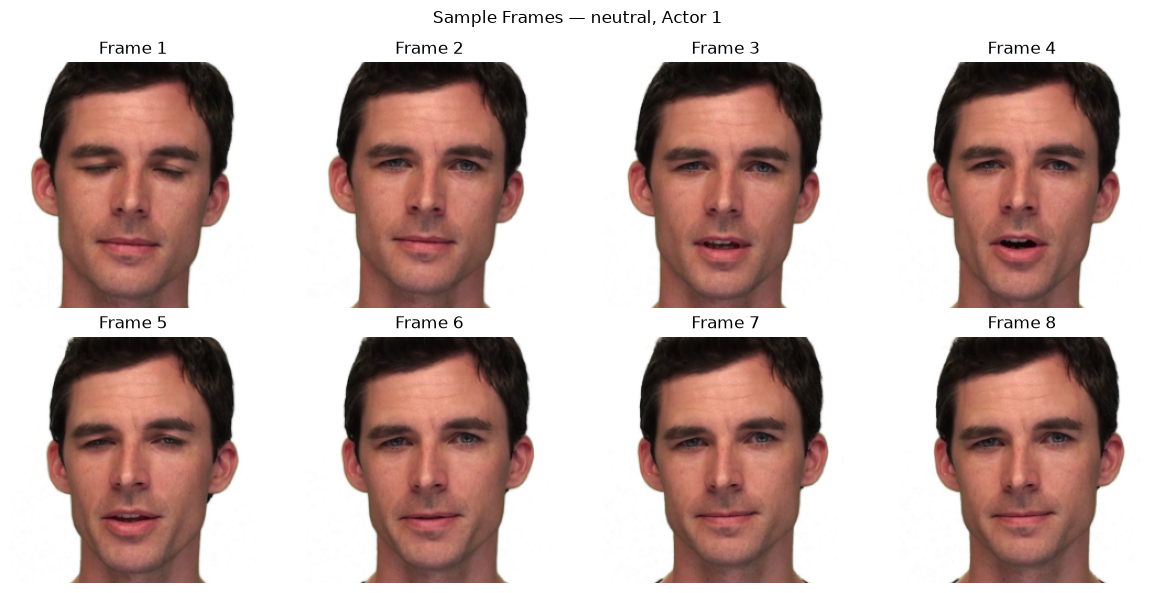

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(video[i])
    ax.set_title(f"Frame {i + 1}")
    ax.axis("off")

plt.suptitle(
    f"Sample Frames — {sample['emotion']}, Actor {sample['actor_id']}"
)
plt.tight_layout()
plt.show()